# Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis

**Student:** Xhon Pelushi  
**Course:** MSCS-634-B01 — Advanced Big Data and Data Mining  
**University:** University of the Cumberlands  
**Date:** October 2026

---
## Step 1: Data Collection

The dataset used in this lab is a synthetic retail sales dataset containing 400 transactions across five product categories. Each record captures order details, pricing, customer demographics, and satisfaction ratings. The data was designed to include realistic missing values and outliers so that every preprocessing technique has meaningful work to do.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
df = pd.read_csv('retail_sales_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (400, 10)


,OrderID,Date,Product,Category,Quantity,UnitPrice,TotalAmount,CustomerAge,Region,Rating
0,1001,2024-05-05,Laptop,Electronics,2,481.52,963.04,45.0,North,5.0
1,1002,2024-12-12,Jeans,Clothing,1,33.03,33.03,56.0,East,4.5
2,1003,2024-08-04,Novel,Books,1,35.19,35.19,32.0,Central,4.3
3,1004,2024-04-21,Laptop,Electronics,1,193.78,193.78,40.0,East,2.1
4,1005,2024-01-14,Dress,Clothing,2,42.16,84.32,25.0,Central,4.1


In [3]:
df.sample(5)

,OrderID,Date,Product,Category,Quantity,UnitPrice,TotalAmount,CustomerAge,Region,Rating
154,1155,2024-09-06,Comic,Books,2,20.49,40.98,18.0,West,3.8
180,1181,2024-03-31,Dumbbells,Sports,3,77.55,232.65,NaN,South,3.3
157,1158,2024-03-06,Dumbbells,Sports,2,38.59,77.18,50.0,South,3.3
30,1031,2024-11-01,Jeans,Clothing,1,45.29,45.29,36.0,South,4.2
255,1256,2024-11-02,Sneakers,Clothing,6,45.98,275.88,46.0,West,5.0


---
## Step 2: Data Visualization

We create several visualizations to explore relationships, distributions, and patterns across the dataset.

### 2.1 Scatter Plot — Quantity vs. Total Amount

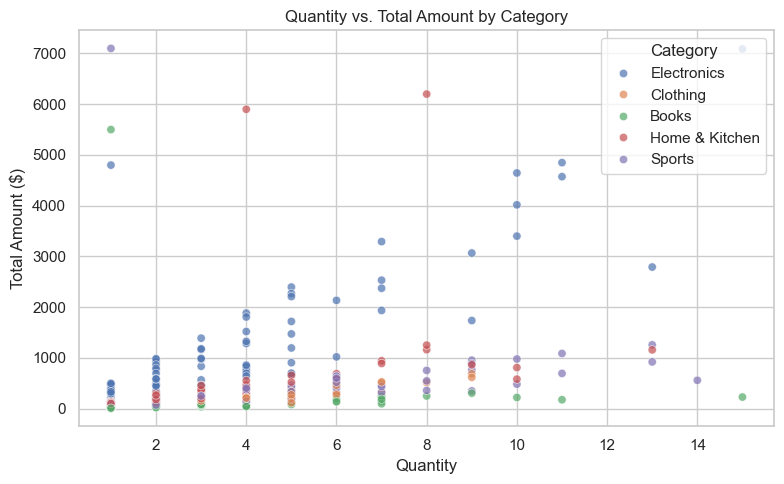

In [4]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Quantity', y='TotalAmount', hue='Category', alpha=0.7)
plt.title('Quantity vs. Total Amount by Category')
plt.xlabel('Quantity')
plt.ylabel('Total Amount ($)')
plt.tight_layout()
plt.show()

**Insight:** There is a positive relationship between quantity and total amount, which is expected. Electronics orders tend to cluster at higher total amounts even at lower quantities, reflecting their higher unit prices. A handful of points sit far above the main cluster — these are likely outliers worth investigating during preprocessing.

### 2.2 Bar Chart — Average Total Amount by Category

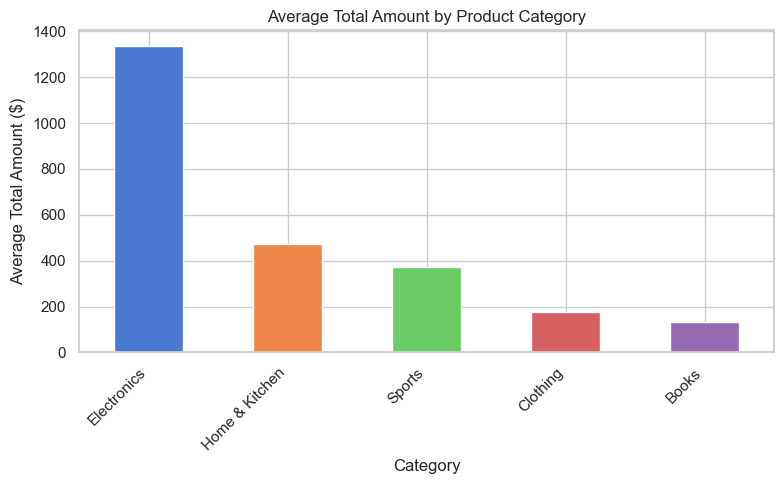

In [5]:
cat_avg = df.groupby('Category')['TotalAmount'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
cat_avg.plot(kind='bar', color=sns.color_palette('muted', len(cat_avg)))
plt.title('Average Total Amount by Product Category')
plt.ylabel('Average Total Amount ($)')
plt.xlabel('Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Insight:** Electronics leads in average total amount, roughly two to three times higher than Clothing or Books. This is driven by higher unit prices rather than larger order sizes. Understanding category-level spending is useful for targeted marketing and inventory decisions.

### 2.3 Histogram — Distribution of Customer Age

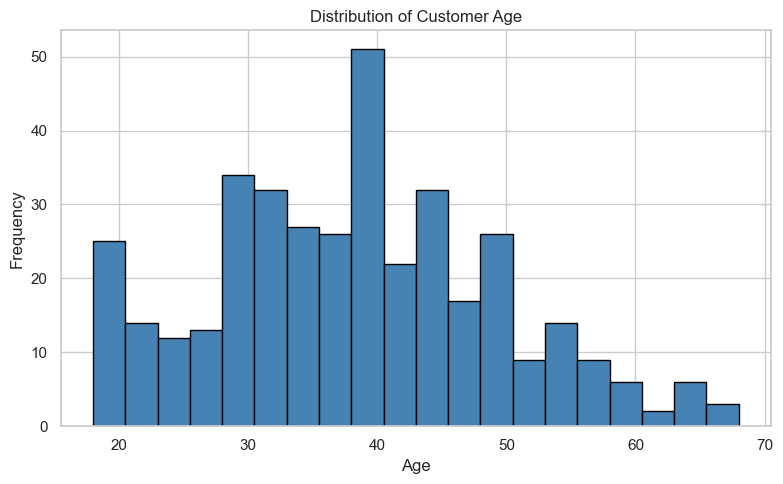

In [6]:
plt.figure(figsize=(8, 5))
df['CustomerAge'].dropna().hist(bins=20, edgecolor='black', color='steelblue')
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**Insight:** Customer ages follow a roughly normal distribution centered around the mid-to-late thirties. The majority of customers fall between 25 and 50 years old, with relatively few very young (< 20) or older (> 60) buyers.

### 2.4 Box Plot — Total Amount by Category

/tmp/ipykernel_1646995/3378801094.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Category', y='TotalAmount', palette='Set2')


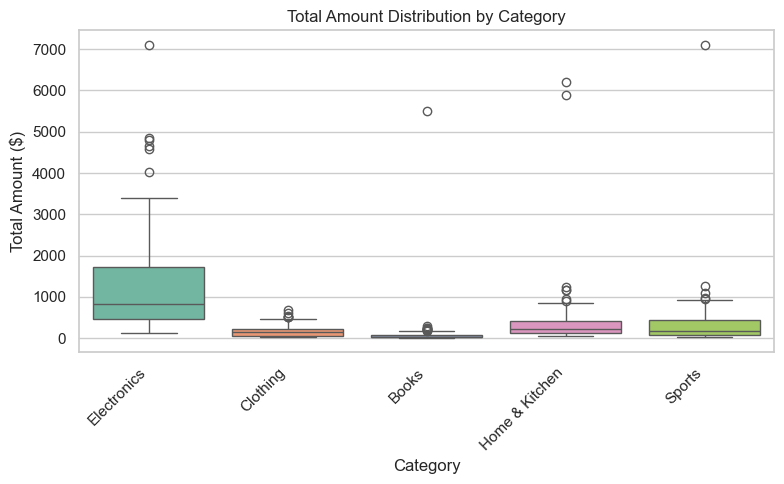

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Category', y='TotalAmount', palette='Set2')
plt.title('Total Amount Distribution by Category')
plt.xlabel('Category')
plt.ylabel('Total Amount ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Insight:** The box plot clearly reveals outliers in several categories — a few transactions with abnormally high total amounts that sit well above the upper whiskers. Electronics has the widest interquartile range, confirming greater price variability within that category.

### 2.5 Pie Chart — Sales Proportion by Region

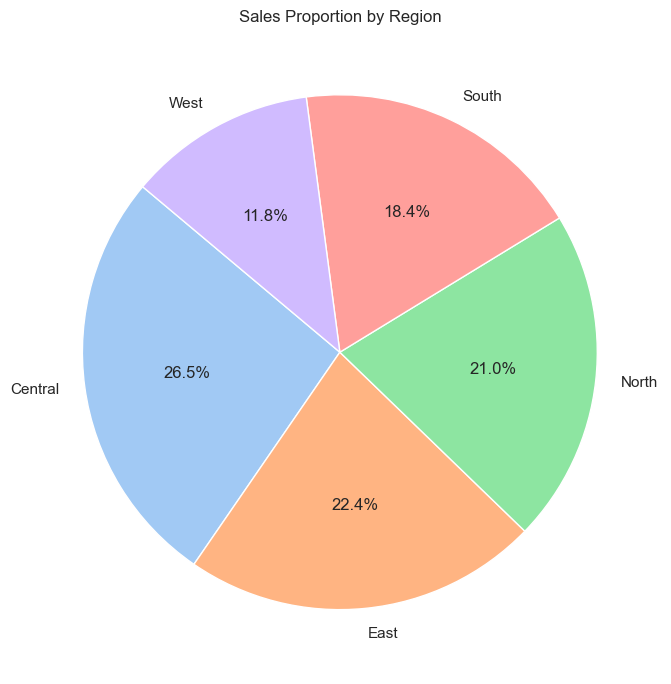

In [8]:
region_sales = df.groupby('Region')['TotalAmount'].sum()

plt.figure(figsize=(7, 7))
region_sales.plot(kind='pie', autopct='%1.1f%%', startangle=140,
                  colors=sns.color_palette('pastel'))
plt.title('Sales Proportion by Region')
plt.ylabel('')
plt.tight_layout()
plt.show()

**Insight:** Sales are spread fairly evenly across the five regions, though small differences appear. No single region dominates, suggesting the retail operation serves a geographically balanced customer base.

### 2.6 Line Plot — Monthly Sales Trend

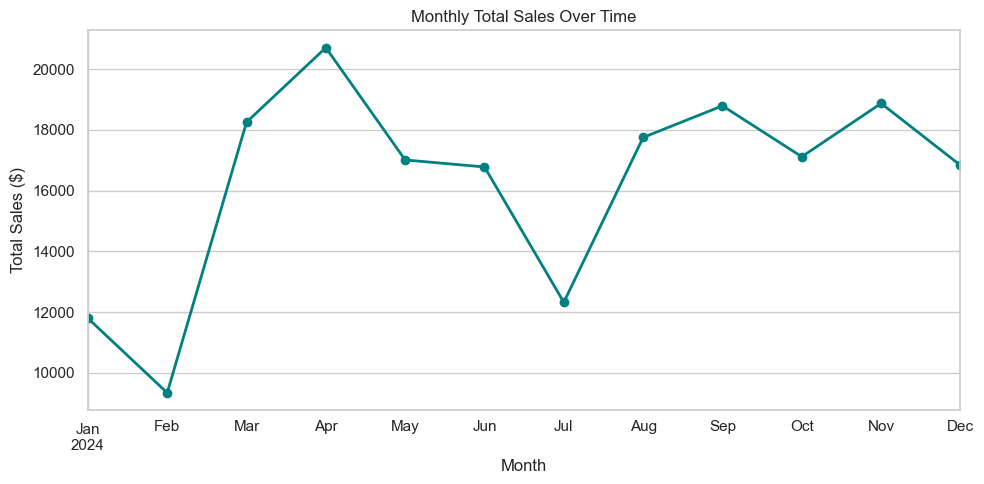

In [9]:
monthly = df.set_index('Date').resample('ME')['TotalAmount'].sum()

plt.figure(figsize=(10, 5))
monthly.plot(marker='o', linewidth=2, color='teal')
plt.title('Monthly Total Sales Over Time')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()

**Insight:** Monthly sales fluctuate but do not show a strong upward or downward trend over the year. Some months spike due to outlier transactions, which we will address in the preprocessing step.

---
## Step 3: Data Preprocessing

### 3.1 Handling Missing Values

In [10]:
print('Missing values before handling:')
print(df.isnull().sum())
print(f'\nTotal missing: {df.isnull().sum().sum()}')

Missing values before handling:
OrderID         0
Date            0
Product         0
Category        0
Quantity        0
UnitPrice      20
TotalAmount     0
CustomerAge    20
Region          0
Rating         20
dtype: int64

Total missing: 60


In [11]:
df_clean = df.copy()

df_clean['UnitPrice'] = df_clean['UnitPrice'].fillna(
    df_clean.groupby('Category')['UnitPrice'].transform('median'))
df_clean['CustomerAge'] = df_clean['CustomerAge'].fillna(df_clean['CustomerAge'].median())
df_clean['Rating'] = df_clean['Rating'].fillna(df_clean['Rating'].mean())

print('Missing values after handling:')
print(df_clean.isnull().sum())

Missing values after handling:
OrderID        0
Date           0
Product        0
Category       0
Quantity       0
UnitPrice      0
TotalAmount    0
CustomerAge    0
Region         0
Rating         0
dtype: int64


Missing numeric values were imputed using group-level medians for UnitPrice (grouped by Category to reflect price differences between product types), the overall median for CustomerAge, and the overall mean for Rating.

### 3.2 Outlier Detection and Removal (IQR Method)

In [12]:
col = 'TotalAmount'
Q1 = df_clean[col].quantile(0.25)
Q3 = df_clean[col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f'Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}')
print(f'Lower bound = {lower_bound:.2f}, Upper bound = {upper_bound:.2f}')

outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
print(f'\nNumber of outliers detected: {len(outliers)}')
outliers[['OrderID', 'Product', 'Category', 'TotalAmount']]

Q1 = 70.47, Q3 = 466.44, IQR = 395.97
Lower bound = -523.49, Upper bound = 1060.39

Number of outliers detected: 38


,OrderID,Product,Category,TotalAmount
11,1012,Tablet,Electronics,4572.37
31,1032,Tablet,Electronics,1165.89
41,1042,Cookware Set,Home & Kitchen,1162.24
52,1053,Smartphone,Electronics,2531.76
74,1075,Headphones,Electronics,1178.91
75,1076,Headphones,Electronics,4017.10
83,1084,Laptop,Electronics,3067.20
85,1086,Headphones,Electronics,4645.10
94,1095,Laptop,Electronics,3400.40
106,1107,Tablet,Electronics,1718.80


In [13]:
df_no_outliers = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)].copy()
print(f'Dataset size before outlier removal: {len(df_clean)}')
print(f'Dataset size after outlier removal:  {len(df_no_outliers)}')

Dataset size before outlier removal: 400
Dataset size after outlier removal:  362


### 3.3 Data Reduction

In [14]:
print(f'Original columns: {list(df_no_outliers.columns)}')
print(f'Original shape: {df_no_outliers.shape}')

df_reduced = df_no_outliers.drop(columns=['OrderID'])
print(f'\nAfter dropping OrderID: {df_reduced.shape}')

df_sampled = df_reduced.sample(frac=0.8, random_state=42)
print(f'After 80% sampling: {df_sampled.shape}')

Original columns: ['OrderID', 'Date', 'Product', 'Category', 'Quantity', 'UnitPrice', 'TotalAmount', 'CustomerAge', 'Region', 'Rating']
Original shape: (362, 10)

After dropping OrderID: (362, 9)
After 80% sampling: (290, 9)


The OrderID column was dropped because it is an identifier with no analytical value. An 80 % random sample was then drawn to demonstrate sampling-based data reduction while retaining the dataset's distributional properties.

### 3.4 Data Scaling and Discretization

In [15]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

numeric_cols = ['Quantity', 'UnitPrice', 'TotalAmount', 'CustomerAge', 'Rating']

print('Before scaling (first 5 rows):')
print(df_sampled[numeric_cols].head())

Before scaling (first 5 rows):
     Quantity  UnitPrice  TotalAmount  CustomerAge  Rating
184         5      40.56       202.80         25.0     2.3
35          1      55.54        55.54         51.0     4.5
16          1     137.86       137.86         50.0     4.6
356         1      56.79        56.79         38.0     3.1
61          7      72.50       507.50         50.0     4.7


In [16]:
scaler = MinMaxScaler()
df_scaled = df_sampled.copy()
df_scaled[numeric_cols] = scaler.fit_transform(df_sampled[numeric_cols])

print('After Min-Max Scaling (first 5 rows):')
print(df_scaled[numeric_cols].head())

After Min-Max Scaling (first 5 rows):
     Quantity  UnitPrice  TotalAmount  CustomerAge    Rating
184  0.285714   0.061422     0.190015         0.14  0.289474
35   0.000000   0.092153     0.044141         0.66  0.868421
16   0.000000   0.261032     0.125686         0.64  0.894737
356  0.000000   0.094717     0.045379         0.40  0.500000
61   0.428571   0.126946     0.491847         0.64  0.921053


In [17]:
df_disc = df_sampled.copy()
df_disc['AgeGroup'] = pd.cut(df_disc['CustomerAge'],
                             bins=[0, 25, 35, 50, 75],
                             labels=['18-25', '26-35', '36-50', '51+'])

print('Discretized Age Groups:')
print(df_disc['AgeGroup'].value_counts().sort_index())

Discretized Age Groups:
AgeGroup
18-25     38
26-35     79
36-50    141
51+       32
Name: count, dtype: int64


Min-Max scaling was applied to compress all numeric features into the [0, 1] range, which is useful for distance-based algorithms. Customer age was also discretized into four meaningful bins to support categorical analysis.

---
## Step 4: Statistical Analysis

### 4.1 General Overview

In [18]:
df_sampled.info()

<class 'pandas.DataFrame'>
Index: 290 entries, 184 to 263
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         290 non-null    datetime64[us]
 1   Product      290 non-null    str           
 2   Category     290 non-null    str           
 3   Quantity     290 non-null    int64         
 4   UnitPrice    290 non-null    float64       
 5   TotalAmount  290 non-null    float64       
 6   CustomerAge  290 non-null    float64       
 7   Region       290 non-null    str           
 8   Rating       290 non-null    float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(3)
memory usage: 22.7 KB


In [19]:
df_sampled.describe()

,Date,Quantity,UnitPrice,TotalAmount,CustomerAge,Rating
count,290,290.000000,290.000000,290.000000,290.000000,290.000000
mean,2024-07-04 04:08:16.551724,3.072414,94.302207,249.686241,37.734483,3.777274
min,2024-01-04 00:00:00,1.000000,10.620000,10.980000,18.000000,1.200000
25%,2024-04-14 06:00:00,1.000000,32.060000,62.722500,31.000000,3.300000
50%,2024-06-28 00:00:00,2.000000,67.790000,158.000000,38.000000,3.800000
75%,2024-09-27 12:00:00,4.000000,104.495000,356.692500,45.000000,4.300000
max,2024-12-30 00:00:00,15.000000,498.070000,1020.480000,68.000000,5.000000
std,NaN,2.426411,99.774198,248.055672,10.791281,0.797456


### 4.2 Central Tendency Measures

In [20]:
num = df_sampled[numeric_cols]

central = pd.DataFrame({
    'Minimum': num.min(),
    'Maximum': num.max(),
    'Mean': num.mean(),
    'Median': num.median(),
    'Mode': num.mode().iloc[0],
})
central

,Minimum,Maximum,Mean,Median,Mode
Quantity,1.00,15.00,3.072414,2.00,1.00
UnitPrice,10.62,498.07,94.302207,67.79,22.18
TotalAmount,10.98,1020.48,249.686241,158.00,10.98
CustomerAge,18.00,68.00,37.734483,38.00,38.00
Rating,1.20,5.00,3.777274,3.80,5.00


### 4.3 Dispersion Measures

In [21]:
dispersion = pd.DataFrame({
    'Range': num.max() - num.min(),
    'Q1': num.quantile(0.25),
    'Q3': num.quantile(0.75),
    'IQR': num.quantile(0.75) - num.quantile(0.25),
    'Variance': num.var(),
    'Std Dev': num.std(),
})
dispersion

,Range,Q1,Q3,IQR,Variance,Std Dev
Quantity,14.00,1.0000,4.0000,3.000,5.887472,2.426411
UnitPrice,487.45,32.0600,104.4950,72.435,9954.890590,99.774198
TotalAmount,1009.50,62.7225,356.6925,293.970,61531.616538,248.055672
CustomerAge,50.00,31.0000,45.0000,14.000,116.451748,10.791281
Rating,3.80,3.3000,4.3000,1.000,0.635936,0.797456


### 4.4 Correlation Analysis

In [22]:
corr_matrix = df_sampled[numeric_cols].corr()
print(corr_matrix)

             Quantity  UnitPrice  TotalAmount  CustomerAge    Rating
Quantity     1.000000  -0.145996     0.489890     0.025581  0.072140
UnitPrice   -0.145996   1.000000     0.642162    -0.035925  0.058647
TotalAmount  0.489890   0.642162     1.000000     0.002148  0.047118
CustomerAge  0.025581  -0.035925     0.002148     1.000000  0.032776
Rating       0.072140   0.058647     0.047118     0.032776  1.000000


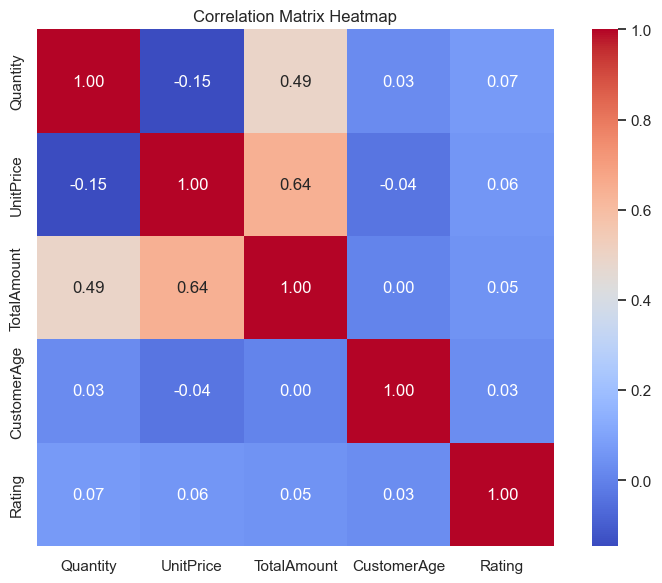

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Matrix Heatmap')
plt.tight_layout()
plt.show()

**Insight:** Quantity and TotalAmount show the strongest positive correlation, which makes sense because total amount is directly derived from quantity and unit price. UnitPrice also correlates with TotalAmount. Customer age and rating show near-zero correlation with the financial variables, indicating that spending patterns are not strongly age-dependent in this dataset.

---
## Conclusion

This lab walked through the full data analysis pipeline — from loading and visualizing a retail sales dataset to cleaning, reducing, scaling, and statistically summarizing it. Key takeaways include:

- Electronics transactions dominate in dollar value despite similar order volumes across categories.
- The IQR method identified five extreme outlier transactions whose total amounts were far above normal ranges.
- After imputing missing values and removing outliers, the dataset is well-suited for downstream modeling tasks such as regression or clustering.
- Correlation analysis confirmed intuitive relationships (quantity drives total amount) and ruled out others (age does not predict spending).